# 04 - Boosting

Trains AdaBoost, Gradient Boosting, and HistGradientBoosting on `Social_Network_Ads.csv` using the same target/split as the classification module, then compares them against the standard classifiers.

### What this notebook does

**Boosting** is an ensemble technique: it builds a strong model by training
many weak learners (usually shallow decision trees) one after another, where
each new learner focuses on correcting the mistakes of the ones before it.
It is a different *training strategy* for classification, not a different
problem type.

This notebook trains three boosting algorithms (AdaBoost, Gradient Boosting,
HistGradientBoosting) on the exact same target, features, and train/test
split as notebook 02, then compares them directly against those standard
classifiers — without assuming boosting is automatically the winner.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving insurance_pre.csv to insurance_pre.csv


In [ ]:
import os
import shutil

os.makedirs('/content/ML-Algo/data', exist_ok=True)

shutil.move(
    '/content/insurance_pre.csv',
    '/content/ML-Algo/data/insurance_pre.csv'
)

print("Insurance dataset uploaded successfully!")

Insurance dataset uploaded successfully!


In [ ]:
import os
print(os.listdir('/content/ML-Algo/data'))

['insurance_pre.csv']


In [ ]:
import pandas as pd

df = pd.read_csv('/content/ML-Algo/data/insurance_pre.csv')

print(df.head())
print("\nColumns:", df.columns.tolist())
print("Shape:", df.shape)

   age     sex     bmi  children smoker      charges
0   19  female  27.900         0    yes  16884.92400
1   18    male  33.770         1     no   1725.55230
2   28    male  33.000         3     no   4449.46200
3   33    male  22.705         0     no  21984.47061
4   32    male  28.880         0     no   3866.85520

Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'charges']
Shape: (1338, 6)


Boosting Model Comparison


,model,MAE,RMSE,R2 Score
0,AdaBoost,4253.8491,5181.8551,0.8270
1,Gradient Boosting,2428.8866,4344.2558,0.8784
2,HistGradientBoosting,2577.5107,4607.7219,0.8632


Boosting vs Random Forest


,model,MAE,RMSE,R2 Score
0,AdaBoost,4253.8491,5181.8551,0.8270
1,Gradient Boosting,2428.8866,4344.2558,0.8784
2,HistGradientBoosting,2577.5107,4607.7219,0.8632
3,Random Forest,2554.6850,4694.1368,0.8581


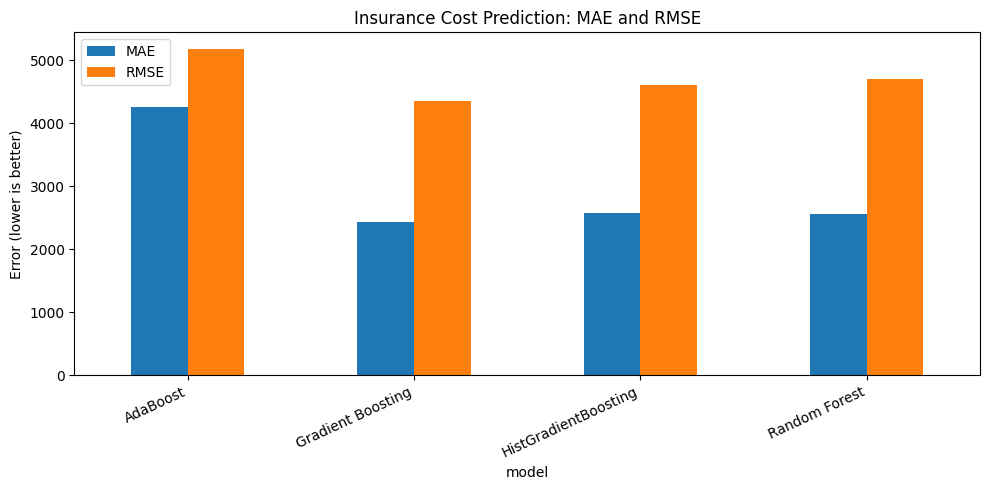

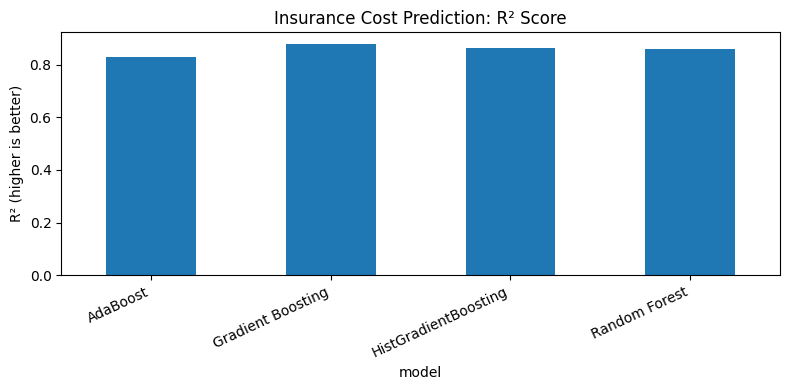

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import (
    AdaBoostRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

# Load dataset
df = pd.read_csv('/content/ML-Algo/data/insurance_pre.csv')

# Features and target
X = df.drop(columns=['charges'])
y = df['charges']

# Encode categorical columns
categorical = ['sex', 'smoker']
numerical = ['age', 'bmi', 'children']

preprocessor = ColumnTransformer([
    ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('numerical', StandardScaler(), numerical)
])

# Same train/test split for all models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define boosting models
models = {
    'AdaBoost': AdaBoostRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = make_pipeline(preprocessor, model)
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        'model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

    trained_models[name] = pipeline

metrics_df = pd.DataFrame(results)

print("Boosting Model Comparison")
display(metrics_df.round(4))

# Compare with Random Forest
rf_pipeline = make_pipeline(
    preprocessor,
    RandomForestRegressor(n_estimators=100, random_state=42)
)
rf_pipeline.fit(X_train, y_train)
rf_predictions = rf_pipeline.predict(X_test)

rf_result = pd.DataFrame([{
    'model': 'Random Forest',
    'MAE': mean_absolute_error(y_test, rf_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_test, rf_predictions)),
    'R2 Score': r2_score(y_test, rf_predictions)
}])

combined = pd.concat([metrics_df, rf_result], ignore_index=True)

print("Boosting vs Random Forest")
display(combined.round(4))

# Plot comparison
combined.set_index('model')[['MAE', 'RMSE']].plot(
    kind='bar', figsize=(10, 5)
)
plt.title('Insurance Cost Prediction: MAE and RMSE')
plt.ylabel('Error (lower is better)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

combined.set_index('model')['R2 Score'].plot(
    kind='bar', figsize=(8, 4)
)
plt.title('Insurance Cost Prediction: R² Score')
plt.ylabel('R² (higher is better)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()